# **Neural Network**
Bike sharing systems are new generation of traditional bike rentals where whole process from membership, rental and return back has become automatic. Through these systems, user is able to easily rent a bike from a particular position and return back at another position. Currently, there are about over 500 bike-sharing programs around the world which is composed of over 500 thousands bicycles. Today, there exists great interest in these systems due to their important role in traffic, environmental and health issues. 

Apart from interesting real world applications of bike sharing systems, the characteristics of data being generated by these systems make them attractive for the research. Opposed to other transport services such as bus or subway, the duration of travel, departure and arrival position is explicitly recorded in these systems. This feature turns bike sharing system into a virtual sensor network that can be used for sensing mobility in the city. Hence, it is expected that most of important events in the city could be detected via monitoring these data.

# **TASK 1: Develop the neural network model for predicting the count of rental bikes.​**
As experienced in regression exercise, the regression models did not perform well on the task of the count of rental bikes prediction. We look into the deep learing and This task will use the simple 2-layers fully connected neural network model as the example and guide you through the step-by-step process of the whole process of the model development.


## Load and prepare the data
Start by loading the dataset and shaping it so that it's suitable for use in machine learning. This dataset contains the hourly and daily count of rental bikes between years 2011 and 2012 in Capital bikeshare system with the corresponding weather and seasonal information.

In [1]:
import pandas as pd

# Define the URL from which to fetch the CSV data.
url = 'https://raw.githubusercontent.com/zhenliangma/Applied-AI-in-Transportation/master/Exercise_7_Neural_networks/Exercise7BikeSharing.csv'

# Use pandas to read the CSV data from the specified URL and store it in a DataFrame 'df'.
# df = pd.read_csv(url)
# Display the first 10 rows of the DataFrame 'df'.
df = pd.read_csv('Exercise7BikeSharing.csv')
df.head(10)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
5,6,2011-01-01,1,0,1,5,0,6,0,2,0.24,0.2576,0.75,0.0896,0,1,1
6,7,2011-01-01,1,0,1,6,0,6,0,1,0.22,0.2727,0.80,0.0000,2,0,2
7,8,2011-01-01,1,0,1,7,0,6,0,1,0.20,0.2576,0.86,0.0000,1,2,3
8,9,2011-01-01,1,0,1,8,0,6,0,1,0.24,0.2879,0.75,0.0000,1,7,8
9,10,2011-01-01,1,0,1,9,0,6,0,1,0.32,0.3485,0.76,0.0000,8,6,14


How many rows and columns does the dataset contain?

In [2]:
df.shape

(17379, 17)

Are any of the columns missing values?

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


## Feature engineering
- Target: `cnt` (count of total rental bikes including both casual and registered)
- Predictors: weather (`temp`, `atemp`, `hum`, `windspeed`, `weathersit`), calendar (`hr`, `weekday`, `workingday`, `holiday`, `season`), and `yr`.
- We keep it simple; you can expand features (e.g., interactions) later.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
target = 'cnt'
features = [
    'temp','atemp','hum','windspeed','weathersit',
    'hr','weekday','workingday','holiday','season','yr'
]

X = df[features].copy()
y = df[target].astype(float)


# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale features (important for NN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

**(Optional) quick baseline (Linear Regression)**

In [6]:
# A super-fast baseline, just for context
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

rmse_lr = root_mean_squared_error(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print({"LR_RMSE": rmse_lr, "LR_MAE": mae_lr, "LR_R2": r2_lr})

{'LR_RMSE': 139.20960076354183, 'LR_MAE': 104.79577059911452, 'LR_R2': 0.3879974354720257}


## Create a neural network model
Now it's time build a neural network and train it with the data prepared in the previous exercise. We'll try neural network first and use cross-validation its meaasure accuracy.

In [47]:
#pip install tensorflow

In [8]:
import tensorflow as tf
#from tensorflow.keras.models import Sequential
Sequential=tf.keras.models.Sequential
#from tensorflow.keras.layers import Dense
Dense=tf.keras.layers.Dense
Input=tf.keras.layers.Input

# Create a Sequential model, which is a linear stack of layers.
model=Sequential()
# define the input shape explicitly, and an input dimension of 11, then add the first dense layer
model.add(Input(shape=(11,)))
# Add a Dense layer with 32 units, ReLU activation, .
model.add(Dense(32, activation='relu'))
# Add another Dense layer with 64 units and ReLU activation.
model.add(Dense(64, activation='relu'))
# Add a final Dense layer with 1 unit (typically used for regression tasks).
model.add(Dense(1))
# Compile the model with the Adam optimizer, Mean Absolute Error (MAE) loss function,
# and MAE metric to be used during training.
model.compile(optimizer='adam', loss='mae', metrics=['mae'])
# Display a summary of the model architecture, including the number of parameters.
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,561 (10.00 KB)

 Trainable params: 2,561 (10.00 KB)

 Non-trainable params: 0 (0.00 B)

## Training and prediction
We split the dataset into a training and a test dataset. Then, we fit the neural network model with the training dataset and predict the values for the test dataset.

Epoch 1/200
348/348 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 146.9192 - mae: 146.9192 - val_loss: 101.9752 - val_mae: 101.9752
Epoch 2/200
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 100.5358 - mae: 100.5358 - val_loss: 98.4614 - val_mae: 98.4614
Epoch 3/200
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 98.4816 - mae: 98.4816 - val_loss: 96.8346 - val_mae: 96.8346
Epoch 4/200
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 97.3088 - mae: 97.3088 - val_loss: 95.8840 - val_mae: 95.8840
Epoch 5/200
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 95.9248 - mae: 95.9248 - val_loss: 94.3746 - val_mae: 94.3746
Epoch 6/200
348/348 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 94.0415 - mae: 94.0415 - val_loss: 92.4041 - val_mae: 92.4041
Epoch 7/200
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 91.8894 - mae: 91.8894 - val_loss: 90.5189 - val_mae: 90.5189
Epoch 8/200
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 89.6627 - mae: 89.6627 - val_loss: 88.4405 - val_mae: 88.4405
Epoch 9/20

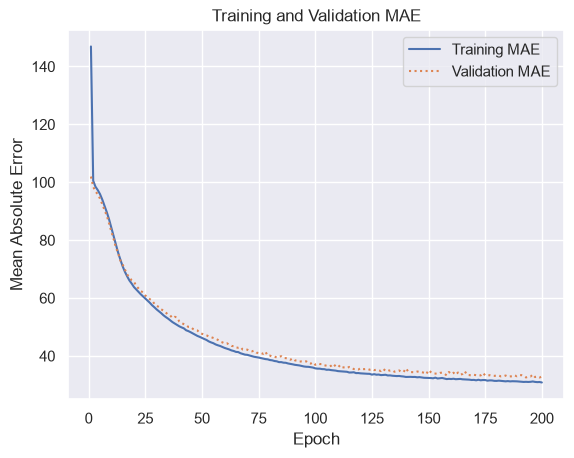

In [9]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

# Fit the model to the training data, specifying validation split, epochs, and batch size.
hist = model.fit(X_train_scaled, y_train, validation_split=0.2, epochs=200, batch_size=32)
# Set the style of the plots using Seaborn.
sns.set_theme()  # sns.set() is deprecated, use sns.set_theme() instead
# Extract the training and validation Mean Absolute Error (MAE) from the training history.
err = hist.history['mae']
val_err = hist.history['val_mae']
# Define the number of epochs.
epochs = range(1, len(err) + 1)
# Plot the Training MAE and Validation MAE over epochs.
plt.plot(epochs, err, '-', label='Training MAE')
plt.plot(epochs, val_err, ':', label='Validation MAE')
plt.title('Training and Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('Mean Absolute Error')
plt.legend(loc='upper right')
plt.plot()
# Use the trained model to predict on the test data.
y_pred = model.predict(X_test_scaled)

## Evaluate the model
You can evaluate the model's performance using various metrics, such as Mean Absolute Error (MAE), Mean Squared Error (MSE), or R-squared (R2).

In [11]:
from sklearn.metrics import root_mean_squared_error, mean_squared_error, r2_score

# Calculate the Mean Absolute Error (MAE) between the true and predicted values.
mae_nn = mean_absolute_error(y_test, y_pred)
# Calculate the Root Mean Squared Error (RMSE) between the true and predicted values.
mse_nn = mean_squared_error(y_test, y_pred)
rmse_nn = root_mean_squared_error(y_test, y_pred) # the argument squared=False is used in the olde version of sklearn, but in the newer version, we can use root_mean_squared_error directly.
# Calculate the R-squared (R2) score, a measure of how well the model explains the variance in the data.
r2_nn = r2_score(y_test, y_pred)
# Print the calculated metrics.
print(f"Mean Absolute Error of NN: {mae_nn}")
print(f"Root Mean Squared Error of NN: {rmse_nn}")
print(f"R-squared of NN: {r2_nn}")

Mean Absolute Error of NN: 32.24115701762678
Root Mean Squared Error of NN: 51.84149809176809
R-squared of NN: 0.9151269220588144


## Compare Metrics (optional)
we compare the performance of NN with baseline linear regression.

In [51]:
import pandas as pd
results = pd.DataFrame([
    {'Model': 'Linear Regression', 'RMSE': rmse_lr, 'MAE': mae_lr, 'R2': r2_lr},
    {'Model': 'Neural Net', 'RMSE': rmse_nn, 'MAE': mae_nn, 'R2': r2_nn},
])
results

,Model,RMSE,MAE,R2
0,Linear Regression,139.209601,104.795771,0.387997
1,Neural Net,50.076617,31.037855,0.920807


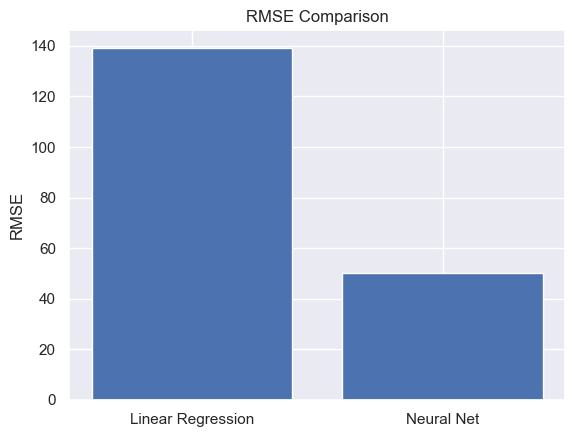

In [52]:
# Bar chart of RMSE
plt.figure()
plt.bar(results['Model'], results['RMSE'])
plt.ylabel('RMSE')
plt.title('RMSE Comparison')
plt.show()

# **Task 2: Practical NN training techniques**
The task will illustrate some useful NN training techniques, including saving and loading the trained model, using the callback function to save the best model, and adding dropout layers.



Epoch 1: val_mae improved from None to 32.08847, saving model to weights.best.keras

Epoch 2: val_mae improved from 32.08847 to 31.84473, saving model to weights.best.keras

Epoch 3: val_mae improved from 31.84473 to 31.50190, saving model to weights.best.keras

Epoch 4: val_mae did not improve from 31.50190

Epoch 5: val_mae did not improve from 31.50190

Epoch 6: val_mae did not improve from 31.50190

Epoch 7: val_mae improved from 31.50190 to 31.43166, saving model to weights.best.keras

Epoch 8: val_mae did not improve from 31.43166

Epoch 9: val_mae did not improve from 31.43166

Epoch 10: val_mae did not improve from 31.43166

Epoch 11: val_mae improved from 31.43166 to 31.40373, saving model to weights.best.keras

Epoch 12: val_mae improved from 31.40373 to 31.27052, saving model to weights.best.keras

Epoch 13: val_mae did not improve from 31.27052

Epoch 14: val_mae did not improve from 31.27052

Epoch 15: val_mae improved from 31.27052 to 31.26427, saving model to weights.be

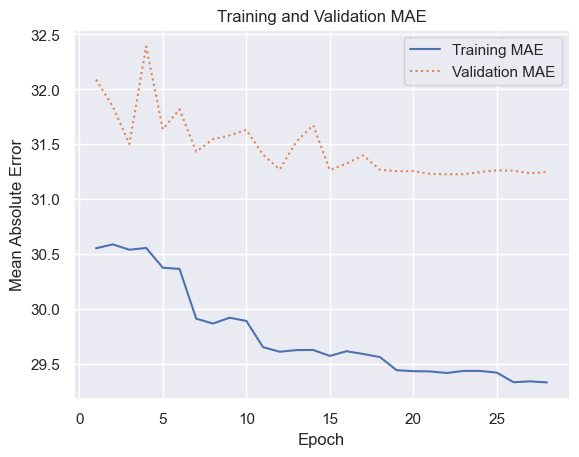

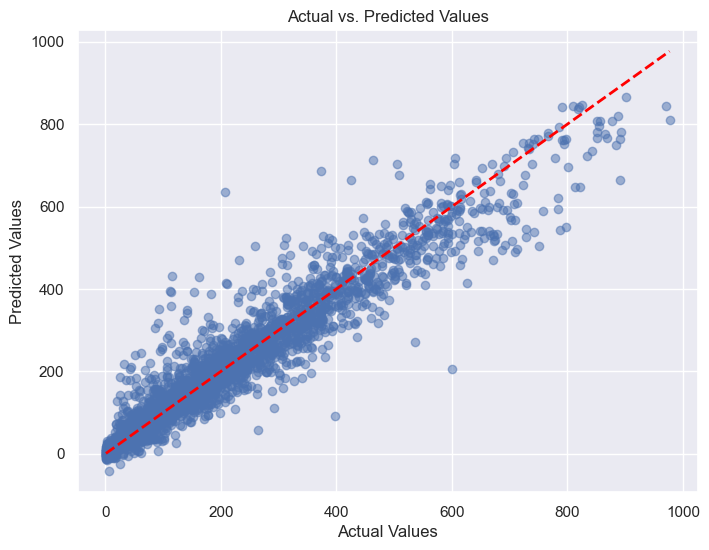

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

Sequential = tf.keras.models.Sequential
Dense = tf.keras.layers.Dense
Dropout = tf.keras.layers.Dropout
Input = tf.keras.layers.Input
EarlyStopping = tf.keras.callbacks.EarlyStopping
ReduceLROnPlateau = tf.keras.callbacks.ReduceLROnPlateau
ModelCheckpoint = tf.keras.callbacks.ModelCheckpoint
load_model = tf.keras.models.load_model

#-------------------------------------------------data preprocessing------------------------------------------------------------------


#-------------------------------------------------network construction-----------------------------------------------------------------

#************************************************Here you can choose to add the dropout layer or not***************************
#
# def construct_network_model():
#   # Create a Sequential model, which is a linear stack of layers.
#   model = Sequential()
#
#   # Define the input shape explicitly, then add the first Dense layer.
#   model.add(Input(shape=(11,)))
#   model.add(Dense(32, activation='relu'))
#
#   # # Add a Dropout layer with a dropout rate of 0.5.
#   # model.add(Dropout(0.5))
#
#   # Add another Dense layer with 64 units and ReLU activation.
#   model.add(Dense(64, activation='relu'))
#
#   # # Add another Dropout layer with a dropout rate of 0.5.
#   # model.add(Dropout(0.5))
#
#   # Add a final Dense layer with 1 unit (typically used for regression tasks).
#   model.add(Dense(1))
#   return model
#
# model=construct_network_model()
# # Compile the model with the Adam optimizer, Mean Absolute Error (MAE) loss function,
# # and MAE metric to be used during training.
# model.compile(optimizer='adam', loss='mae', metrics=['mae'])
#************************************************Here you can choose to add the dropout layer or not*****************

#-------------------------------------------------model train------------------------------------------------------------------
# use the callback function to early stop, learning rate ajusting, save the best model
# Create an EarlyStopping callback to monitor the validation mean absolute error (val_mae).
# It will stop training if val_mae doesn't improve for 5 consecutive epochs and restores the best weights.
early_stop = EarlyStopping(monitor='val_mae', patience=5, restore_best_weights=True)

# Create a ReduceLROnPlateau callback to monitor val_mae.
# It reduces the learning rate by a factor of 0.5 if val_mae doesn't improve for 3 consecutive epochs.
reduce_lr = ReduceLROnPlateau(monitor='val_mae', factor=0.5, patience=3)

# Define the file path where the best model will be saved.
filepath = "weights.best.keras"

# Create a ModelCheckpoint callback to monitor the validation mae (val_mae).
# The callback will save the model's weights only if the validation mae improves.
checkpoint = ModelCheckpoint(filepath, monitor='val_mae', verbose=1, save_best_only=True, mode='min')

# Train the model using the fit method.
hist_2 = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=0,
)

#-------------------------------------------------model evaluation--------------------------------------------------------------------

# Set the style of the plots using Seaborn.
sns.set_theme()

# Extract the training and validation Mean Absolute Error (MAE) from the training history.
err = hist_2.history['mae']
val_err = hist_2.history['val_mae']

# Define the number of epochs.
epochs = range(1, len(err) + 1)

# Plot the Training MAE and Validation MAE over epochs.
plt.plot(epochs, err, '-', label='Training MAE')
plt.plot(epochs, val_err, ':', label='Validation MAE')
plt.title('Training and Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('Mean Absolute Error')
plt.legend(loc='upper right')
plt.show()

# Use the trained model to predict on the test data.
y_pred = model.predict(X_test_scaled)

# Calculate Mean Absolute Error (MAE), Mean Squared Error (MSE), and R-squared (R2) for the predictions.
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('--------------------------------------'+'this is result of the trained model'+"---------------------------------------------")
# Print the calculated metrics.
print(f"Mean Absolute Error: {mae}")
print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2}")

#-------------------------------------------------load model and evaluation--------------------------------------------------------------------
if filepath != "":
    # Load the best model saved by ModelCheckpoint.
    model = load_model(filepath)

    # Use the loaded model to predict on the test data.
    y_pred = model.predict(X_test_scaled)

    # Calculate Mean Absolute Error (MAE), Mean Squared Error (MSE), and R-squared (R2) for the predictions.
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print('--------------------------------------'+'this is result of the model loaded from the local path'+"---------------------------------------------")

    # Print the calculated metrics.
    print(f"Mean Absolute Error: {mae}")
    print(f"Mean Squared Error: {mse}")
    print(f"R-squared: {r2}")

    # Create a scatter plot to visualize the relationship.
    plt.figure(figsize=(8, 6))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")
    plt.title("Actual vs. Predicted Values")
    plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], linestyle='--', color='red', lw=2)
    plt.show()

# **Task 3: Compare the results with a linear regression model**
The task involves comparing the results obtained from the neural network with those from the linear regression model, and we should analyze the reasons behind any differences in the outcomes.

In [ ]:
%matplotlib inline
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

# Set the style of the plots using seaborn.
sns.set_theme()

# Use the trained model to predict on the test data.
y_pred = model.predict(X_test_scaled)

# Calculate Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R2).
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('--------------------------------------'+'this is result of the neural network model'+"---------------------------------------------")
# Print the evaluation metrics.
print(f"Mean Absolute Error: {mae}")
print(f"Root Mean Squared Error: {rmse}")
print(f"R-squared: {r2}")

# Create a Linear Regression model.
model_linear = LinearRegression()
model_linear.fit(X_train_scaled, y_train)
y_pred_linear = model_linear.predict(X_test_scaled)

mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = root_mean_squared_error(y_test, y_pred_linear)
r2_linear = r2_score(y_test, y_pred_linear)

print('--------------------------------------'+'this is result of the linear regression model'+"---------------------------------------------")
print(f"Mean Absolute Error of linear model: {mae_linear}")
print(f"Root Mean Squared Error of linear model: {rmse_linear}")
print(f"R-squared of linear model: {r2_linear}")

109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 581us/step
--------------------------------------this is result of the neural network model---------------------------------------------
Mean Absolute Error: 30.06930317605821
Root Mean Squared Error: 49.33948714279849
R-squared: 0.9231216368659123
--------------------------------------this is result of the linear regression model---------------------------------------------
Mean Absolute Error of linear model: 104.79577059911452
Root Mean Squared Error of linear model: 139.20960076354183
R-squared of linear model: 0.3879974354720257


# **Assignment task: Find the best neural network model for the count of rental bikes prediction (assignment submission)**
Tuning the neural network models (e.g., dropout, sizing of the network), and finding the best neural network model. Suggestions:
- Try adding interaction features (e.g., `hr * workingday`, `weathersit * hum`).
- Tune NN hyperparameters (layers, neurons, learning rate) via `GridSearchCV`.
- Consider more advanced architectures (e.g., gradient boosting, LSTMs for temporal structure).


# Tasks to be completed
### Find the best model for predicting rental bike counts

In [14]:
# Import the required libraried and modules
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
Sequential = tf.keras.models.Sequential
Dense = tf.keras.layers.Dense
Dropout = tf.keras.layers.Dropout
Input = tf.keras.layers.Input
EarlyStopping = tf.keras.callbacks.EarlyStopping
ReduceLROnPlateau = tf.keras.callbacks.ReduceLROnPlateau
ModelCheckpoint = tf.keras.callbacks.ModelCheckpoint
load_model = tf.keras.models.load_model
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split

In [15]:
#====================================================================================
#1) Feature Engineering: Adding interaction features
#====================================================================================
# Create a copy of the features to ensure a clean pipeline
target= 'cnt'
features = ['temp','atemp','hum','windspeed','weathersit',
    'hr','weekday','workingday','holiday','season','yr']

X= df[features].copy()
y= df[target].astype(float)

# Add interaction features to the dataset
# A) hr_workingday: This captures peak commute hours specifically on workdays
X['hr_workingday']=X['hr']*X['workingday']
#  B) weathersit_hum: This captures the combined penality of bad weather and high humidity on bike usage
X['weathersit_hum']=X['weathersit']*X['hum']

# Split dataset in to train=(80%)/test=(20%) 
X_train, X_test, y_train, y_test=train_test_split(X, y, train_size=0.8, test_size=0.2, random_state=42)

# Scale feature for NN stability
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [5]:
print(X_train_scaled.shape[1])

13


In [16]:
# ===================================================================================
# 2) Tunded Neural Network (Sizing and Dropout)
# ===================================================================================
print("---Training Tuned NN---")

# construct a deeper network with varying layer sizes and Dropout
model=Sequential() # We first Create an instance of the Sequential class
# Add input shape explicitly, and make it dynamic to feature training
model.add(Input(shape=(X_train_scaled.shape[1], )))
# Add input layer mapped with  128 neorons
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.2)) # 20% dropout to prevent overfitting
# Hidden layer mapped down to 64 neorons
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.2))
# Hidden layer mapped down to 32 units of neorons
model.add(Dense(32, activation='relu'))
# Linear output layer for regression
model.add(Dense(1))

# Compile the model
model.compile(optimizer='Adam', loss='mae', metrics=['mae'])

# Callback for early stopping to find the best epoch automatically
early_stop=EarlyStopping(monitor="val_mae", patience=10, restore_best_weights=True)
reduce_lr=ReduceLROnPlateau(monitor="val_mae", patience=3, factor=0.5)
filepath_t="weights.best_tuned.keras"
checkpoint_t=ModelCheckpoint(filepath_t, monitor="val_mae", verbose=0, save_best_only=True, mode='min')

# Train the model
hist_tuned=model.fit(X_train_scaled, y_train,
                     validation_split=0.2, 
                     epochs=150, 
                     batch_size=64, 
                     callbacks=[early_stop, reduce_lr, checkpoint_t], 
                     verbose=0)

# Load the best saved model from the checkpoint
best_model=load_model(filepath_t)

---Training Tuned NN---


In [17]:
# predict and evaluate 
y_pred_nn=best_model.predict(X_test_scaled)
mae_nn=mean_absolute_error(y_test, y_pred_nn)
rmse_nn=root_mean_squared_error(y_test, y_pred_nn)
r2_nn=r2_score(y_test, y_pred_nn)

print(f"Tunned NN-MAE:{mae_nn:.2f}, RMSE:{rmse_nn:.2f}, R2:{r2_nn:.4f}")

109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Tunned NN-MAE:40.28, RMSE:65.96, R2:0.8626


In [18]:
#------------------------------------------------------------------------------------
# 3) Gradient Boosting Regressor (GBR) (Advanced Architecture)
#------------------------------------------------------------------------------------
print("---Training Boosting Regressor-----")

gbr=HistGradientBoostingRegressor(random_state=42, max_iter=200)
gbr.fit(X_train, y_train) # Tree models does not need scaled data, so I use the unscaled training feature data

y_pred_gbr=gbr.predict(X_test)
mae_gbr=mean_absolute_error(y_test, y_pred_gbr)
rmse_gbr=root_mean_squared_error(y_test, y_pred_gbr)
r2_gbr=r2_score(y_test, y_pred_gbr)

print(f"Gradient Boost- MAE:{mae_gbr:.2F}, RMSE:{rmse_gbr:.2f}, R2:{r2_gbr:.4f}")

---Training Boosting Regressor-----
Gradient Boost- MAE:24.74, RMSE:39.97, R2:0.9495


In [19]:
#------------------------------------------------------------------------------------
# 4) Compare between Tuned NN and Gradien Booting Regressor (GBR)
#------------------------------------------------------------------------------------

print("\n---Final Model Comparison---")
df_comp=pd.DataFrame([{'Model': 'Tuned Neaural Network', 'MAE':mae_nn, 'RMSE':rmse_nn, 'R2':r2_nn}, 
                      {'Model': 'Gradient Boosting Regressor', 'MAE':mae_gbr, 'RMSE':rmse_gbr, 'R2':r2_gbr}])

# print the datset converted to pandas dataframe in text and set index to False
print(df_comp.to_string(index=False))


---Final Model Comparison---
                      Model       MAE      RMSE       R2
      Tuned Neaural Network 40.275187 65.962771 0.862592
Gradient Boosting Regressor 24.740478 39.971338 0.949544


C:\Users\Alex\AppData\Local\Temp\ipykernel_14248\624362702.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_comp, x='Model', y='R2', palette='viridis')


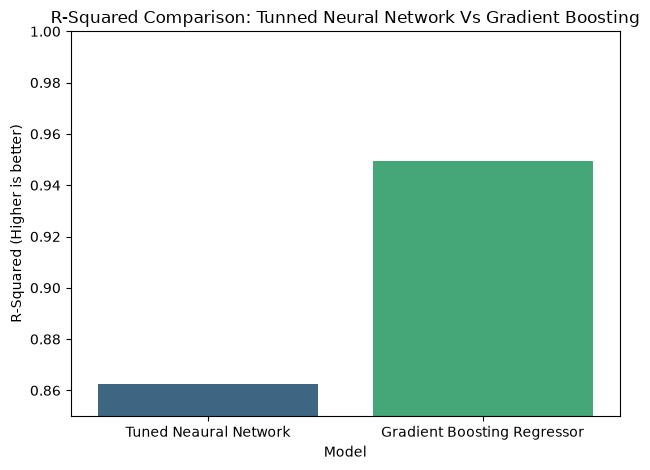

In [20]:
#------------------------------------------------------------------------------------
# 4)Visualize the comparison of R-squared score
#------------------------------------------------------------------------------------

plt.Figure(figsize=(8, 6))
sns.barplot(data=df_comp, x='Model', y='R2', palette='viridis')
plt.title("R-Squared Comparison: Tunned Neural Network Vs Gradient Boosting")
plt.ylabel('R-Squared (Higher is better)')
plt.ylim(0.85, 1)
plt.tight_layout()
plt.show()


In [2]:
#====================================================================================
# 5) Advanced Architecture:LSTM (Long short-term Memory)
#====================================================================================

# This works better for Time Series datasets like GTFS-RT DELAY PREDICTION

# Import the required libraried and modules
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
Sequential = tf.keras.models.Sequential
Dense = tf.keras.layers.Dense
Dropout = tf.keras.layers.Dropout
Input = tf.keras.layers.Input
LSTM=tf.keras.layers.LSTM
EarlyStopping = tf.keras.callbacks.EarlyStopping
ReduceLROnPlateau = tf.keras.callbacks.ReduceLROnPlateau
ModelCheckpoint = tf.keras.callbacks.ModelCheckpoint
load_model = tf.keras.models.load_model
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler




In [3]:

# 1) Feature Engineering (Re-Using the same features)
# Create a copy of the features to ensure a clean pipeline
target= 'cnt'
features = ['temp','atemp','hum','windspeed','weathersit',
    'hr','weekday','workingday','holiday','season','yr']

X_lstm= df[features].copy()
y_lstm= df[target].astype(float).values

# Add interaction features to the dataset
# A) hr_workingday: This captures peak commute hours specifically on workdays
X_lstm['hr_workingday']=X_lstm['hr']*X_lstm['workingday']
#  B) weathersit_hum: This captures the combined penality of bad weather and high humidity on bike usage
X_lstm['weathersit_hum']=X_lstm['weathersit']*X_lstm['hum']

# Scale feature first
scaler_lstm=StandardScaler()
X_scaler_lstm=scaler_lstm.fit_transform(X_lstm)


# Split dataset in to train=(80%)/test=(20%) 
#X_train, X_test, y_train, y_test=train_test_split(X, y, train_size=0.8, test_size=0.2, random_state=42)

# ------------------------------------------------------------------------------------------
# 2) I create the Sequence (so called 'Sliding Window')
# LSTM requires 3D Inputs: (Nu,ber of Samples, Time Steps, Features)
# Hwere I use the previous 5 hours of data to predict the demand in the 6th hours 
# ------------------------------------------------------------------------------------------

# create a fucntion that creates the function
def create_sequence(X, y, time_steps=5):
    Xs, ys=[], []
    for i in range(len(X)-time_steps):
        Xs.append(X[i:(i+time_steps)])
        ys.append(y[i+time_steps])
    return np.array(Xs), np.array(ys)
time_steps=5
X_seq, y_seq=create_sequence(X_scaler_lstm, y_lstm, time_steps=5)

In [4]:
#------------------------------------------------------------------------------------
# 3) Chrpnological Train/Test Split
# I do not use the random_state splitting for time-series LSTMs
# The split must be chronologicall to prenvet predicting the past using the future
#------------------------------------------------------------------------------------

split_idx=int(len(X_seq)*0.8) # 80% train. 20 % test

X_train_seq=X_seq[:split_idx]
X_test_seq=X_seq[split_idx:]
y_train_seq=y_seq[:split_idx]
y_test_seq=y_seq[split_idx:]

print(f"LSTM Input shape:{X_train_seq.shape}") # Should be (samples, 5, 13)

LSTM Input shape:(13899, 5, 13)


In [8]:
#------------------------------------------------------------------------------------
# 4) LSTM Model Construction
#------------------------------------------------------------------------------------

print(f"\n--- Training LSTM Time Series Network---")


model_lstm=Sequential()
model_lstm.add(Input(shape=(X_train_seq.shape[1], X_train_seq.shape[2])))

# LSTM Layer 
model_lstm.add(LSTM(64, activation='relu'))
model_lstm.add(Dropout(0.2))

# Standared Dense Mapping 
model_lstm.add(Dense(32, activation='relu'))
model_lstm.add(Dense(1))

model_lstm.compile(optimizer='Adam', loss='mae', metrics=['mae'])

# Full Callback suite (Save to disk, adjust LR, early stop)
filepath_lstm="lstm_weights.best.keras"

early_stop_lstm=EarlyStopping(monitor='val_mae', patience=5, restore_best_weights=True)
reduce_lr_lstm=ReduceLROnPlateau(monitor='val_mae', factor=0.5, patience=3)
checkpoint_lstm=ModelCheckpoint(filepath_lstm, monitor='val_mae', verbose=1,save_best_only=True, mode='min' )

#7) Train the LSTM
hist_lstm=model_lstm.fit(X_train_seq, y_train_seq,
                         validation_split=0.2,
                         epochs=60,
                         batch_size=64,
                         callbacks=[early_stop_lstm, reduce_lr_lstm, checkpoint_lstm], 
                         verbose=0
                         )

# 8) Load the Best Model from Disk and Evaluate
print("\n--- Loading Best LSTM Model from Disk---")
best_lstm_model=load_model(filepath_lstm)

y_pred_lstm=best_lstm_model.predict(X_test_seq)

mae_lstm=mean_absolute_error(y_test_seq, y_pred_lstm)
rmse_lstm=root_mean_squared_error(y_test_seq,y_pred_lstm)
r2_lstm=r2_score(y_test_seq,y_pred_lstm)

print("\n---- LSTM Model Performance---")
print(f"Mean Absolute Error: {mae_lstm:.2f}")
print(f"Root Mean Squared Error:{rmse_lstm:.2f}")
print(f"R_Squared:{r2_lstm:.4f}")


--- Training LSTM Time Series Network---

Epoch 1: val_mae improved from None to 158.18048, saving model to lstm_weights.best.keras

Epoch 1: finished saving model to lstm_weights.best.keras

Epoch 2: val_mae improved from 158.18048 to 135.06198, saving model to lstm_weights.best.keras

Epoch 2: finished saving model to lstm_weights.best.keras

Epoch 3: val_mae improved from 135.06198 to 97.31867, saving model to lstm_weights.best.keras

Epoch 3: finished saving model to lstm_weights.best.keras

Epoch 4: val_mae improved from 97.31867 to 85.86096, saving model to lstm_weights.best.keras

Epoch 4: finished saving model to lstm_weights.best.keras

Epoch 5: val_mae improved from 85.86096 to 74.20171, saving model to lstm_weights.best.keras

Epoch 5: finished saving model to lstm_weights.best.keras

Epoch 6: val_mae improved from 74.20171 to 65.02293, saving model to lstm_weights.best.keras

Epoch 6: finished saving model to lstm_weights.best.keras

Epoch 7: val_mae improved from 65.02293

In [21]:
# Final Comparisons between the models tested and visualization
comparison_df=pd.DataFrame([{'Model': 'Tuned Neaural Network', 'MAE':mae_nn, 'RMSE':rmse_nn, 'R2':r2_nn}, 
                      {'Model': 'Gradient Boosting Regressor', 'MAE':mae_gbr, 'RMSE':rmse_gbr, 'R2':r2_gbr},
                        {'Model': 'LSTM', 'MAE':mae_lstm, 'RMSE':rmse_lstm, 'R2':r2_lstm}])
# Display the results in the form of Dataframe
print(comparison_df.to_string(index=False))


                      Model       MAE      RMSE       R2
      Tuned Neaural Network 40.275187 65.962771 0.862592
Gradient Boosting Regressor 24.740478 39.971338 0.949544
                       LSTM 55.031332 87.092429 0.844015


C:\Users\Alex\AppData\Local\Temp\ipykernel_14248\941796321.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='R2', data=comparison_df, palette='viridis')


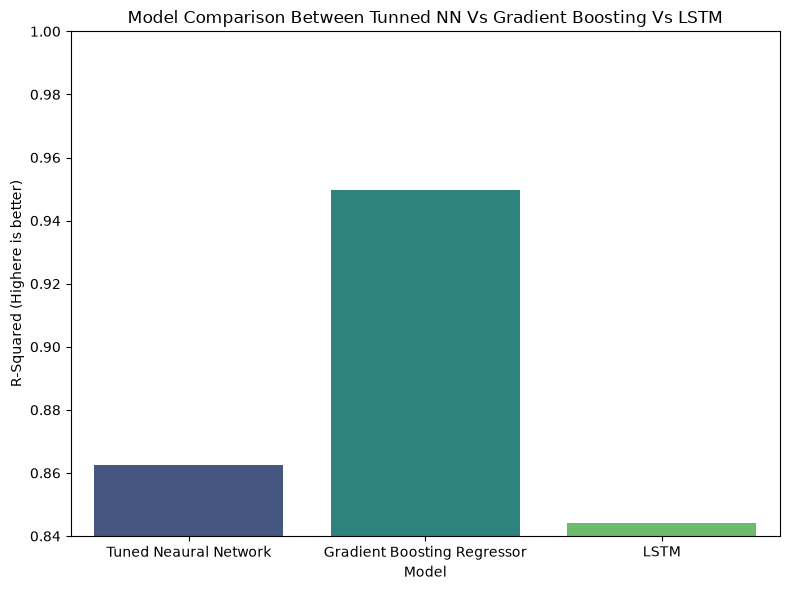

In [22]:
# Visualize the Models Performance using the R-Squared Values
plt.figure(figsize=(8,6))
sns.barplot(x='Model', y='R2', data=comparison_df, palette='viridis')
plt.title("Model Comparison Between Tunned NN Vs Gradient Boosting Vs LSTM")
plt.ylabel("R-Squared (Highere is better)")
plt.ylim(0.84, 1)
plt.tight_layout()
plt.show()

* So, the Final Comparison between results of the Metrics shows that Gradient Boosting Regressor is the best ( MAE: 24.74; RMSE: 39.97; R2: 0.94954) 